### Identifying the Problem
Before diving into the data, it is essential to clearly define the problem. The term 'churn' refers to the number of customers who cease doing business with a company within a given period. For businesses, it is crucial to monitor the churn rate as it directly affects their revenue and overall business performance. In this project, our objective is to analyze the dataset to identify which factors affects churn most and develop an efficient machine learning model that can predict future churns.

The "The Orange Telecom's Churn Dataset" dataset retrieved from Kaggle, represents customers both those who have stopped and those who are still subscribed with the following features:

* State: The state in which the customer resides
* Account length: The duration that the customer has had an account with the company (in days)
* Area code: The customer's area code
* International plan: Indicates whether the customer has an international calling plan (Yes/No)
* Voice mail plan: Indicates whether the customer has a voicemail service (Yes/No)
* Number vmail messages: Number of voice mail messages stored by the customer
* Total day minutes: Total minutes of calls made during daytime
* Total day calls: Total number of calls made during daytime
* Total day charge: Total charges incurred for daytime calls
* Total eve minutes: Total minutes of calls made during evening
* Total eve calls: Total number of calls made during evening
* Total eve charge: Total charges incurred for evening calls
* Total night minutes: Total minutes of calls made during night
* Total night calls: Total number of calls made during night
* Total night charge: Total charges incurred for night calls
* Total intl minutes: Total minutes of international calls
* Total intl calls: Total number of international calls
* Total intl charge: Total charges incurred for international calls
* Customer service calls: Number of times the customer has contacted customer service
* Churn: Indicates whether the customer has churned (True/False)

In [1]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy.stats import chi2_contingency
from plotly.subplots import make_subplots

In [2]:
df = pd.read_csv("../data/churn-bigml-80.csv")

In [3]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(df.head())
display(df.sample(min(5, len(df)), random_state=42))

Rows: 2666 | Columns: 20


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
2087,OH,115,510,Yes,No,0,345.3,81,58.70,203.4,106,17.29,217.5,107,9.79,11.8,8,3.19,1,True
1915,WY,157,415,Yes,No,0,180.4,123,30.67,194.0,98,16.49,227.3,88,10.23,8.4,5,2.27,0,False
479,AZ,84,415,No,No,0,159.0,80,27.03,167.9,128,14.27,167.6,101,7.54,12.3,5,3.32,1,False
1898,FL,105,415,No,No,0,273.8,97,46.55,289.7,106,24.62,269.1,126,12.11,5.8,3,1.57,2,True
741,KY,74,510,Yes,No,0,125.8,103,21.39,207.7,96,17.65,207.4,143,9.33,14.1,4,3.81,1,True


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   str    
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   str    
 4   Voice mail plan         2666 non-null   str    
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   float64
 15

1. Data Completeness: The dataset contains 2,666 rows and 20 columns with zero missing values across all features, so no imputation is needed.
2. Identified Categorical Features: State, International plan, Voice mail plan, and Churn. Features to be encoded.

In [5]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Account length,2666.0,100.620405,39.563974,1.00,73.0000,100.00,127.000,243.00
Area code,2666.0,437.438860,42.521018,408.00,408.0000,415.00,510.000,510.00
Number vmail messages,2666.0,8.021755,13.612277,0.00,0.0000,0.00,19.000,50.00
Total day minutes,2666.0,179.481620,54.210350,0.00,143.4000,179.95,215.900,350.80
Total day calls,2666.0,100.310203,19.988162,0.00,87.0000,101.00,114.000,160.00
Total day charge,2666.0,30.512404,9.215733,0.00,24.3800,30.59,36.700,59.64
Total eve minutes,2666.0,200.386159,50.951515,0.00,165.3000,200.90,235.100,363.70
Total eve calls,2666.0,100.023631,20.161445,0.00,87.0000,100.00,114.000,170.00
Total eve charge,2666.0,17.033072,4.330864,0.00,14.0500,17.08,19.980,30.91
Total night minutes,2666.0,201.168942,50.780323,43.70,166.9250,201.15,236.475,395.00


1. Features magnitudes are different. To be scaled when using distance based algorithms.
2. Few features are not normally distributed.
3. Pricing Rate Disparities Across Time Windows.

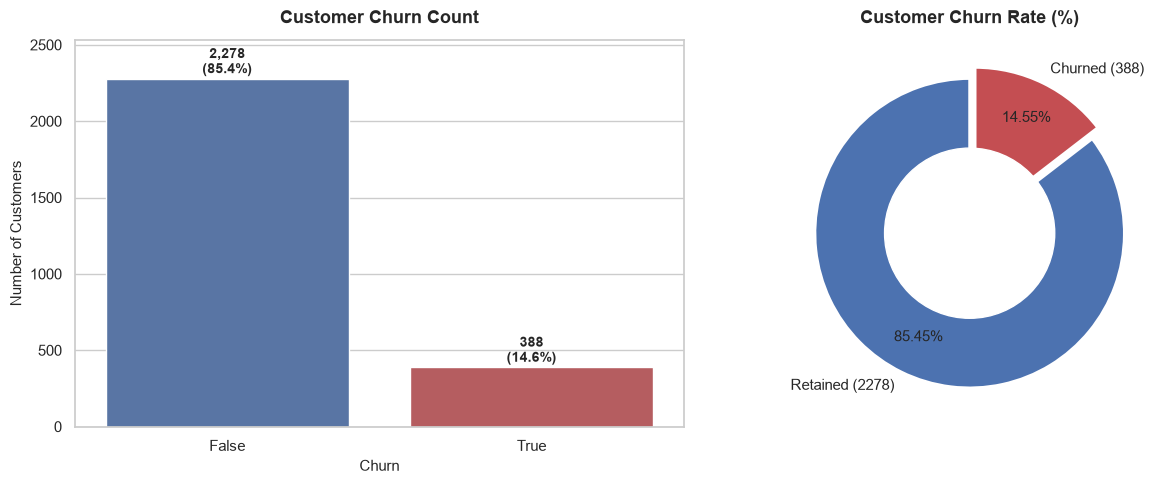

In [6]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax1 = sns.countplot(
    x="Churn",
    data=df,
    palette=["#4C72B0", "#C44E52"],
    hue="Churn",
    legend=False,
    ax=axes[0],
)
axes[0].set_title(
    "Customer Churn Count", fontsize=13, fontweight="bold", pad=12
)
axes[0].set_xlabel("Churn", fontsize=11)
axes[0].set_ylabel("Number of Customers", fontsize=11)

total_rows = len(df)
for p in ax1.patches:
    count = int(p.get_height())
    pct = f"{100 * count / total_rows:.1f}%"
    ax1.annotate(
        f"{count:,}\n({pct})",
        (p.get_x() + p.get_width() / 2.0, count),
        ha="center",
        va="center",
        xytext=(0, 12),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
    )
axes[0].set_ylim(0, total_rows * 0.95)

churn_counts = df["Churn"].value_counts()
colors = ["#4C72B0", "#C44E52"]
explode = (0, 0.08)

axes[1].pie(
    churn_counts,
    labels=[f"Retained ({churn_counts[False]})", f"Churned ({churn_counts[True]})"],
    autopct="%1.2f%%",
    startangle=90,
    colors=colors,
    explode=explode,
    pctdistance=0.75,
    textprops={"fontsize": 11, "fontweight": "normal"},
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)

centre_circle = plt.Circle((0, 0), 0.55, fc="white")
axes[1].add_artist(centre_circle)
axes[1].set_title("Customer Churn Rate (%)", fontsize=13, fontweight="bold", pad=12)

plt.tight_layout()
plt.show()

* Severe Class Imbalance:
  * Retained (False): 2,278 customers (~85.45%)
  * Churned (True): 388 customers (~14.55%)
  * The dataset exhibits an approximate 6:1 ratio between non-churn and churn cases.

* Accuracy Paradox / Baseline Risk:
  * A trivial baseline model predicting "Not Churn" for every single customer would achieve an 85.45% accuracy while completely failing to detect actual churners.
  * Standard accuracy is an inappropriate metric for model evaluation.

* Modeling & Preprocessing Implications:
  * Validation Strategy: Use Stratified K-Fold Cross-Validation (or stratify=y during train-test split) to maintain the 14.55% churn distribution across splits.
  * Evaluation Metrics: Evaluate models using Recall, Precision, F1-Score, and PR-AUC, ROC-AUC.
  * Class Balancing Techniques: Consider tuning class weights (class_weight='balanced in scikit-learn, scale_pos_weight in XGBoost/LightGBM) or applying resampling methods (e.g., SMOTE) if recall on the positive class is low.

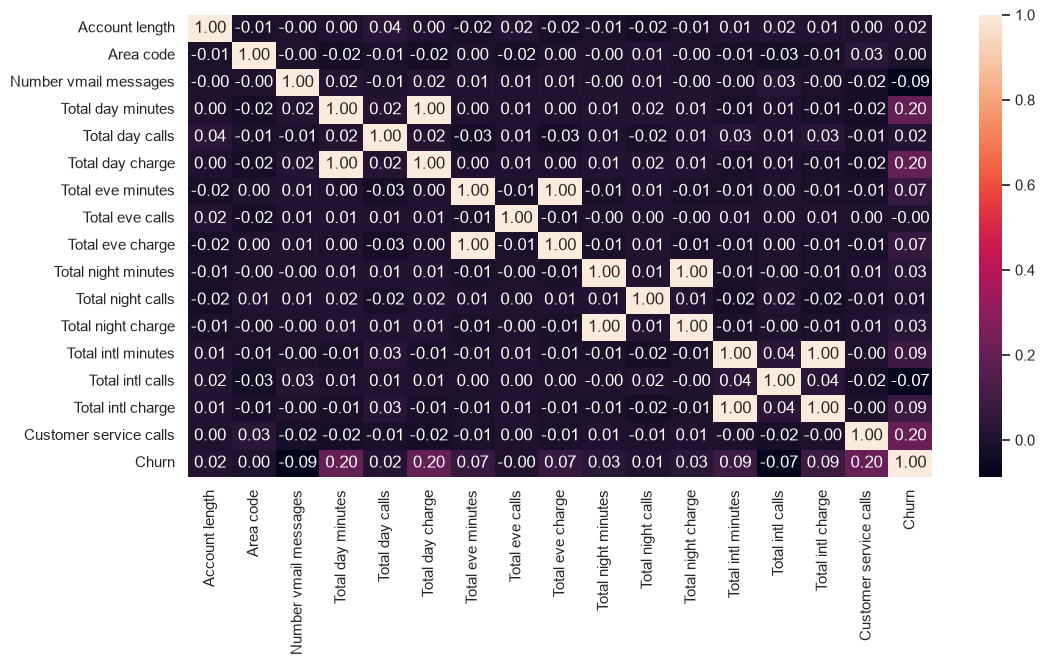

In [7]:
corr = df.corr(numeric_only = True)
plt.figure(figsize = (12,6))
sns.heatmap(corr, annot = True, fmt='.2f' )
plt.show()

* Perfect Multicollinearity is seen. One feature from each pair should be dropped to eliminate multicollinearity.
* Top Churn Drivers (Positive Correlation):

    Customer service calls (r = 0.20): Customers who call customer service repeatedly are significantly more likely to churn. This indicates friction, recurring service issues, or unmet expectations.

    Total day minutes & Total day charge (r = 0.20): Higher daytime usage and associated daytime charges correlate positively with churn. High daytime spenders may be sensitive to price or seeking better flat-rate/unlimited plans elsewhere.

* Usage Independence Across Time Periods
    The correlations between different times of day (day, evening, night, and international) are near 0.00 to -0.03.

    Heavy daytime users are not necessarily heavy evening or night users. Customer usage behavior is distinct across time bands, indicating diverse user personas (e.g., business-hour callers vs. night/social callers).

* Call Volume vs. Call Duration
    Total calls and total minutes within each category (e.g., Total day calls vs. Total day minutes, r = 0.02) show almost no correlation.

    Users making more calls are not necessarily spending more total minutes on the phone; call frequency and average call duration operate independently.


## Univariate Analysis

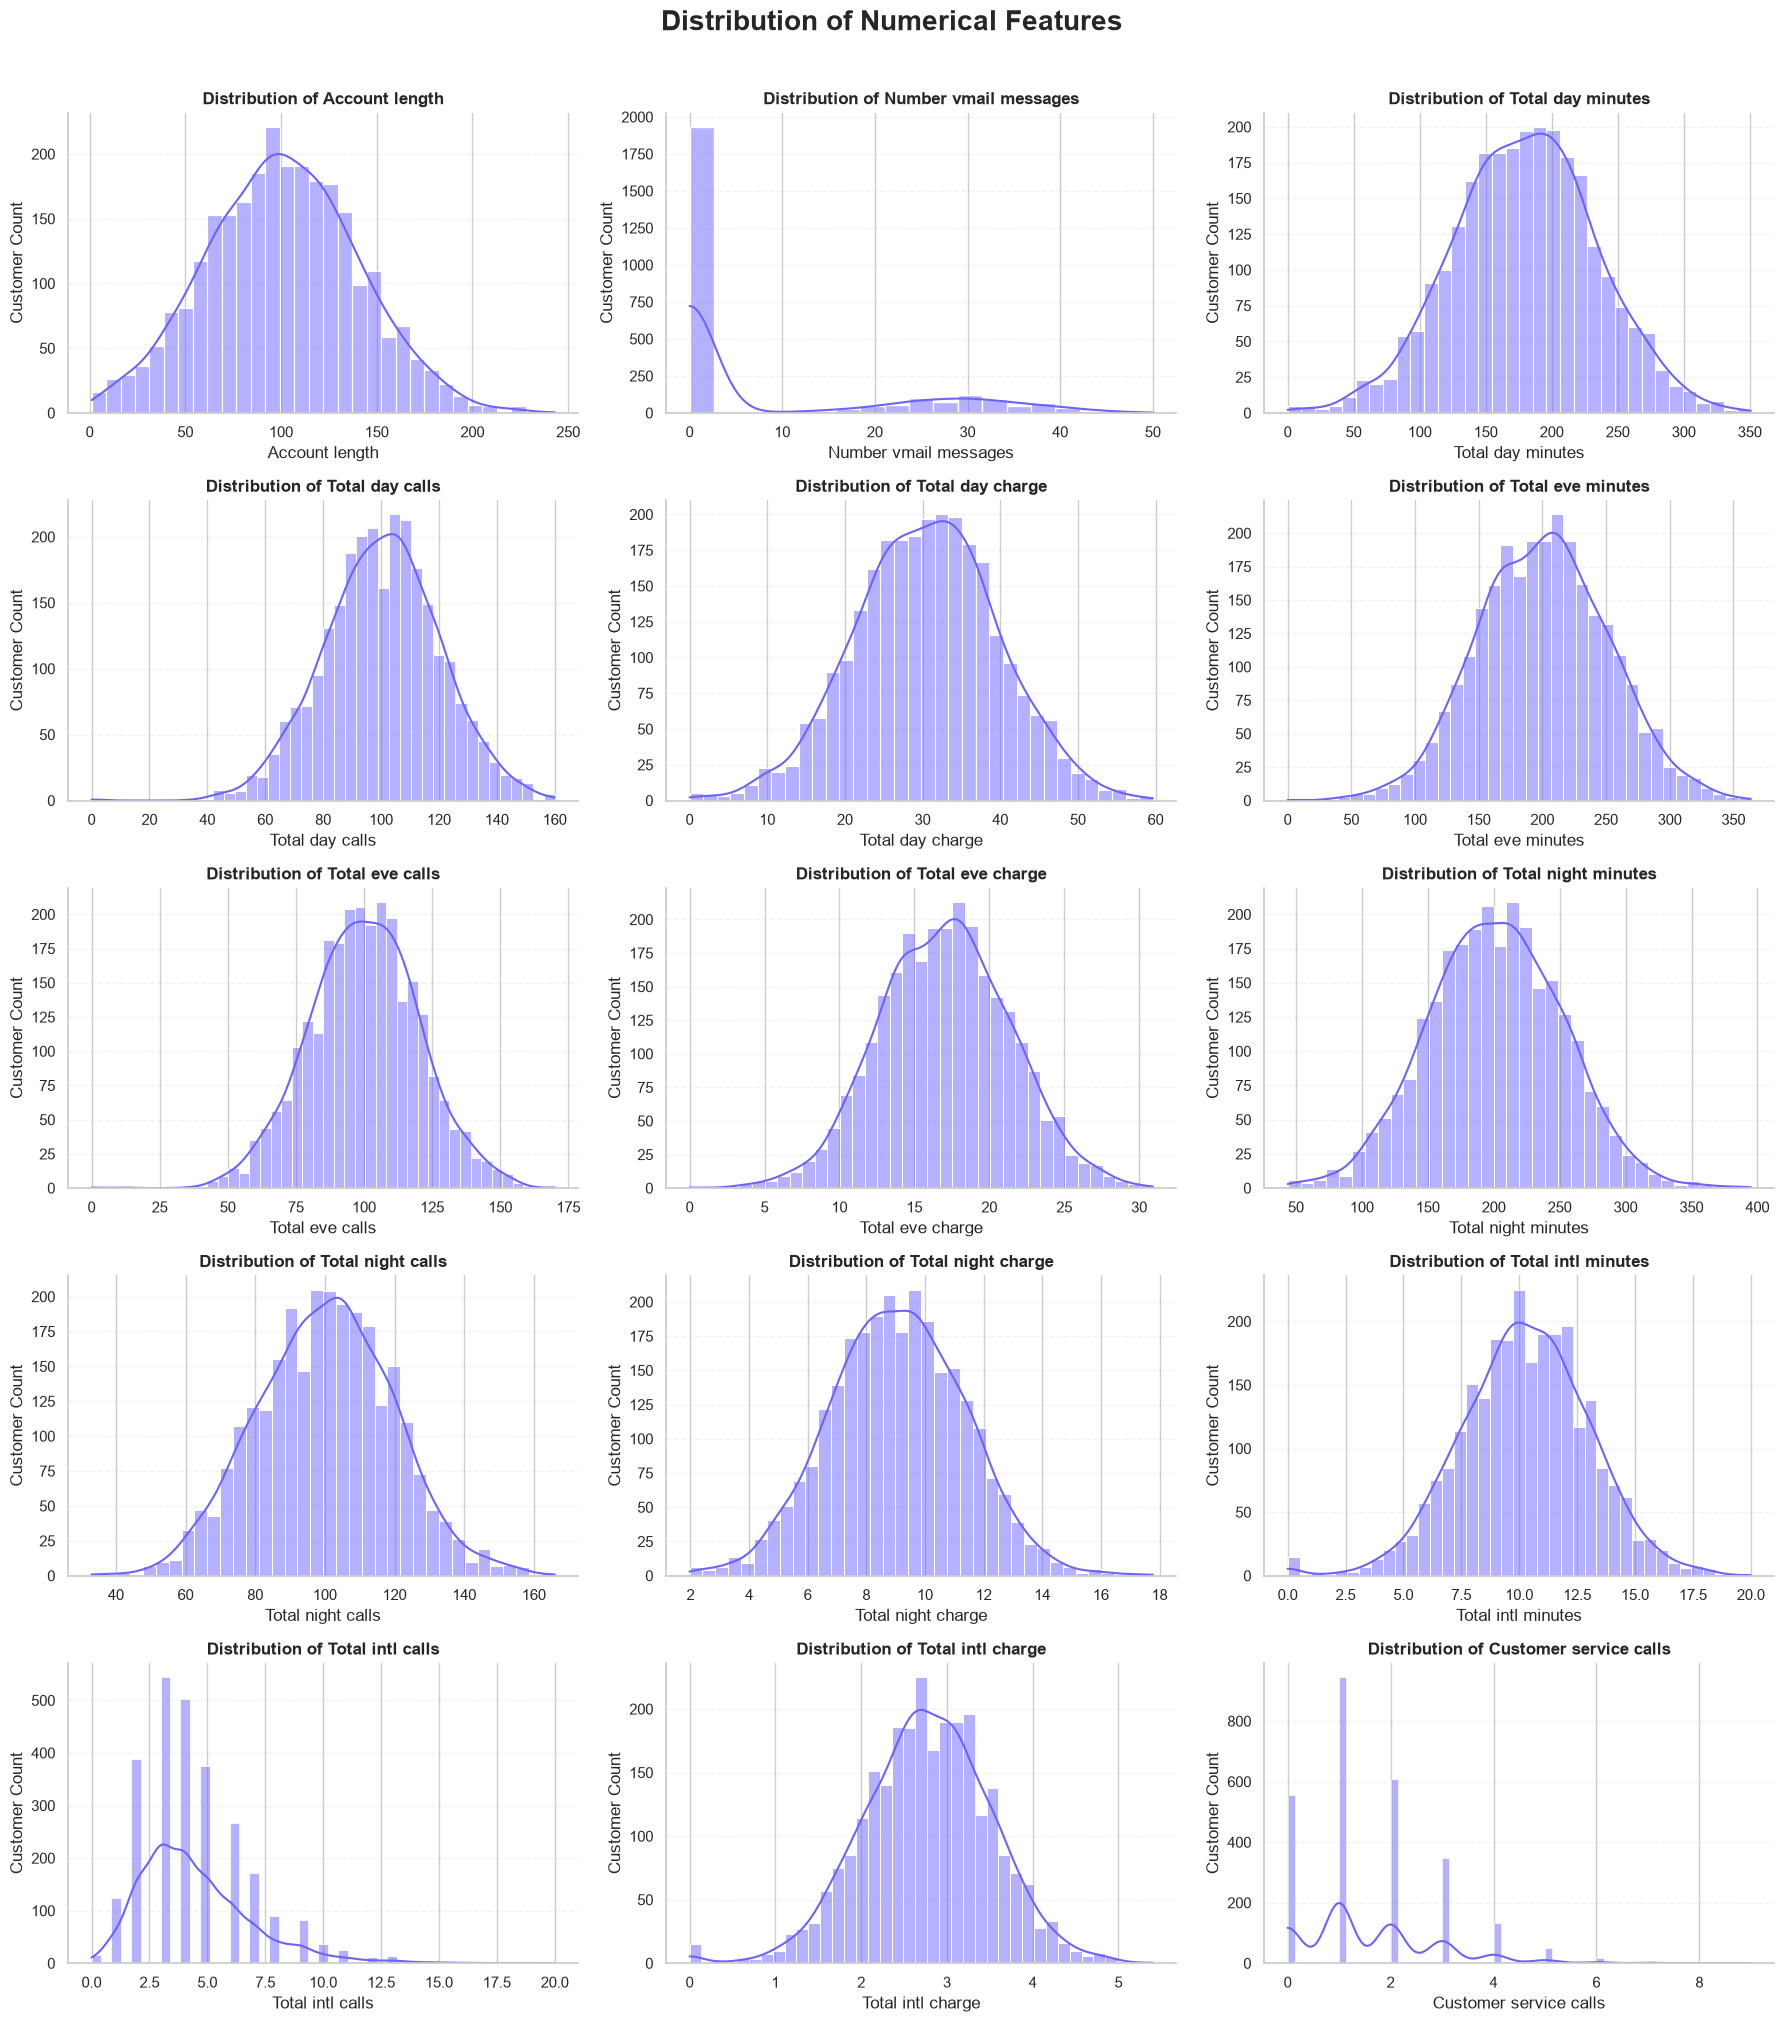

In [8]:
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

numerical_cols = [
    col for col in numerical_cols
    if col != "Area code"
]

n_cols = 3
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, n_rows * 4)
)

axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        color="#6C63FF",
        ax=axes[i],
        edgecolor="white"
    )

    axes[i].set_title(
        f"Distribution of {col}",
        fontsize=12,
        fontweight="bold"
    )
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Customer Count")
    axes[i].grid(axis="y", linestyle="--", alpha=0.25)
    sns.despine(ax=axes[i], top=True, right=True)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=20,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

* Nearly Perfect Normal (Gaussian) Distributions: Total day minutes, Total day charge, Total eve minutes, Total eve charge, Total night minutes, Total night charge, Total intl minutes, Total intl charge, Account length, Total day calls, Total eve calls, and Total night calls. Standardizing is directly suitable for the majority of features because they already fulfill normality assumptions without requiring Log or Box-Cox transformations.
* Number vmail messages: Heavily zero-inflated. A large spike at 0 indicates most customers do not use voicemail, while a secondary small bump between 20 and 40 represents customers with active voicemail usage.
* Right-Skewed Discrete Count Features: Customer service calls and Total intl calls.

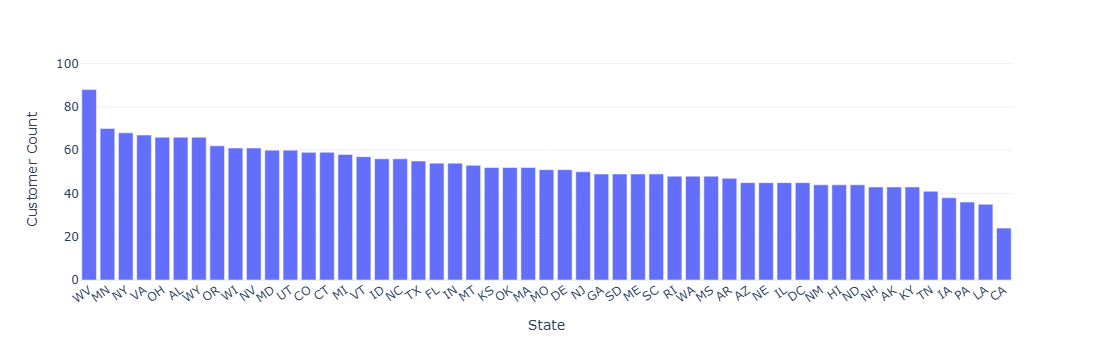

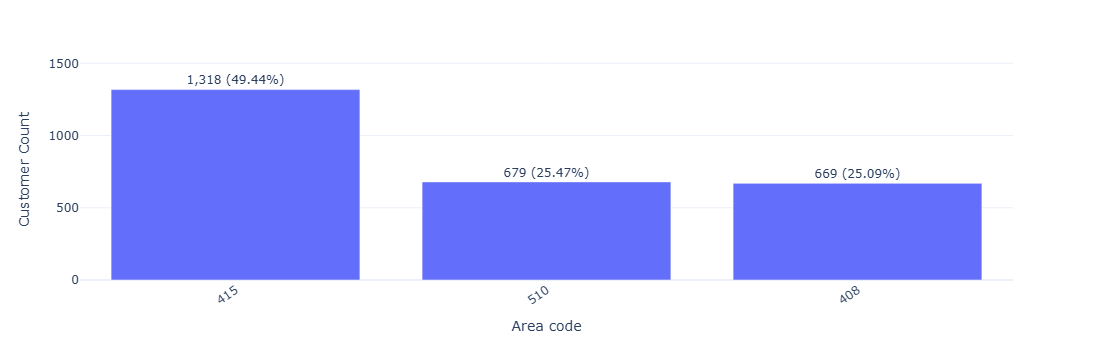

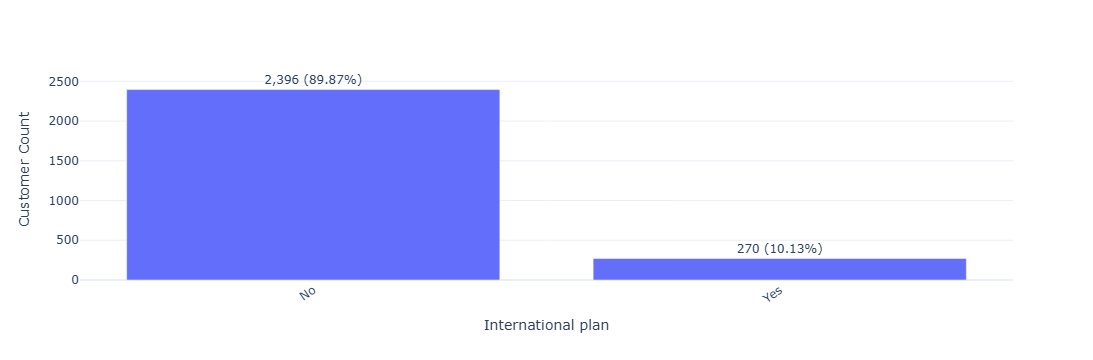

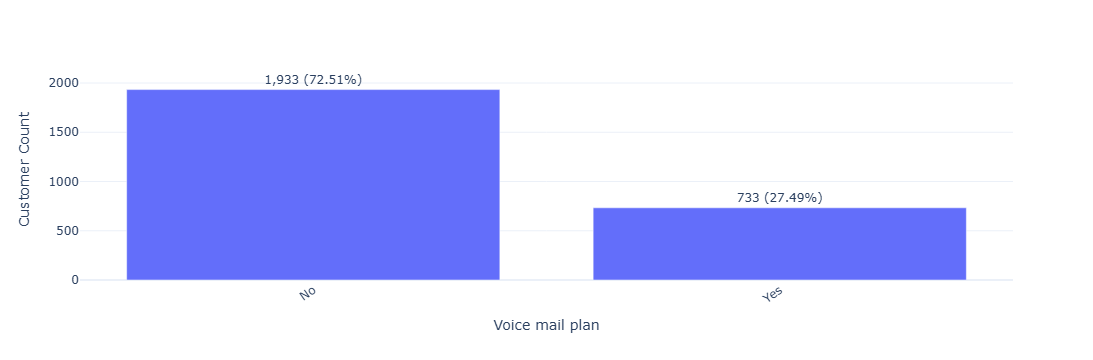

In [9]:
cat_cols = ["State", "Area code", "International plan", "Voice mail plan"]
for col in cat_cols:
    if col in df.columns and df[col].nunique(dropna=False) <= 60:

        counts = df[col].astype(str).value_counts(dropna=False).reset_index()
        counts.columns = [col, "Customers"]

        total_customers = counts["Customers"].sum()
        counts["Rate (%)"] = (counts["Customers"] / total_customers * 100).round(2)

        counts["Label"] = counts.apply(
            lambda r: f"{r['Customers']:,} ({r['Rate (%)']}%)", axis=1
        )
        
        fig = px.bar(
            counts,
            x=col,
            y="Customers",
            text="Label",
            hover_data={"Customers": True, "Rate (%)": ":.2f%", "Label": False},
            template="plotly_white",
        )
        
        fig.update_traces(textposition="outside")
        fig.update_layout(
            xaxis_tickangle=-35,
            yaxis_title="Customer Count",
            uniformtext_minsize=8,
            uniformtext_mode="hide",
        )
        fig.show()

    elif col in df.columns:
        print(f"Skipped {col}: too many categories ({df[col].nunique()})")

* Voice Mail Plan: Moderate Imbalance: 72.51% (1,933 customers) do not have a voicemail plan, while 27.49% (733 customers) have subscribed. This explains the zero-inflation observed earlier in the Number vmail messages histogram (the ~72.5% of non-subscribers account for the massive spike at 0 messages).
* Most customers aren't interested in international calling plan.
* No Single Dominant State: Most states fall tightly within the 40 to 65 customer range.

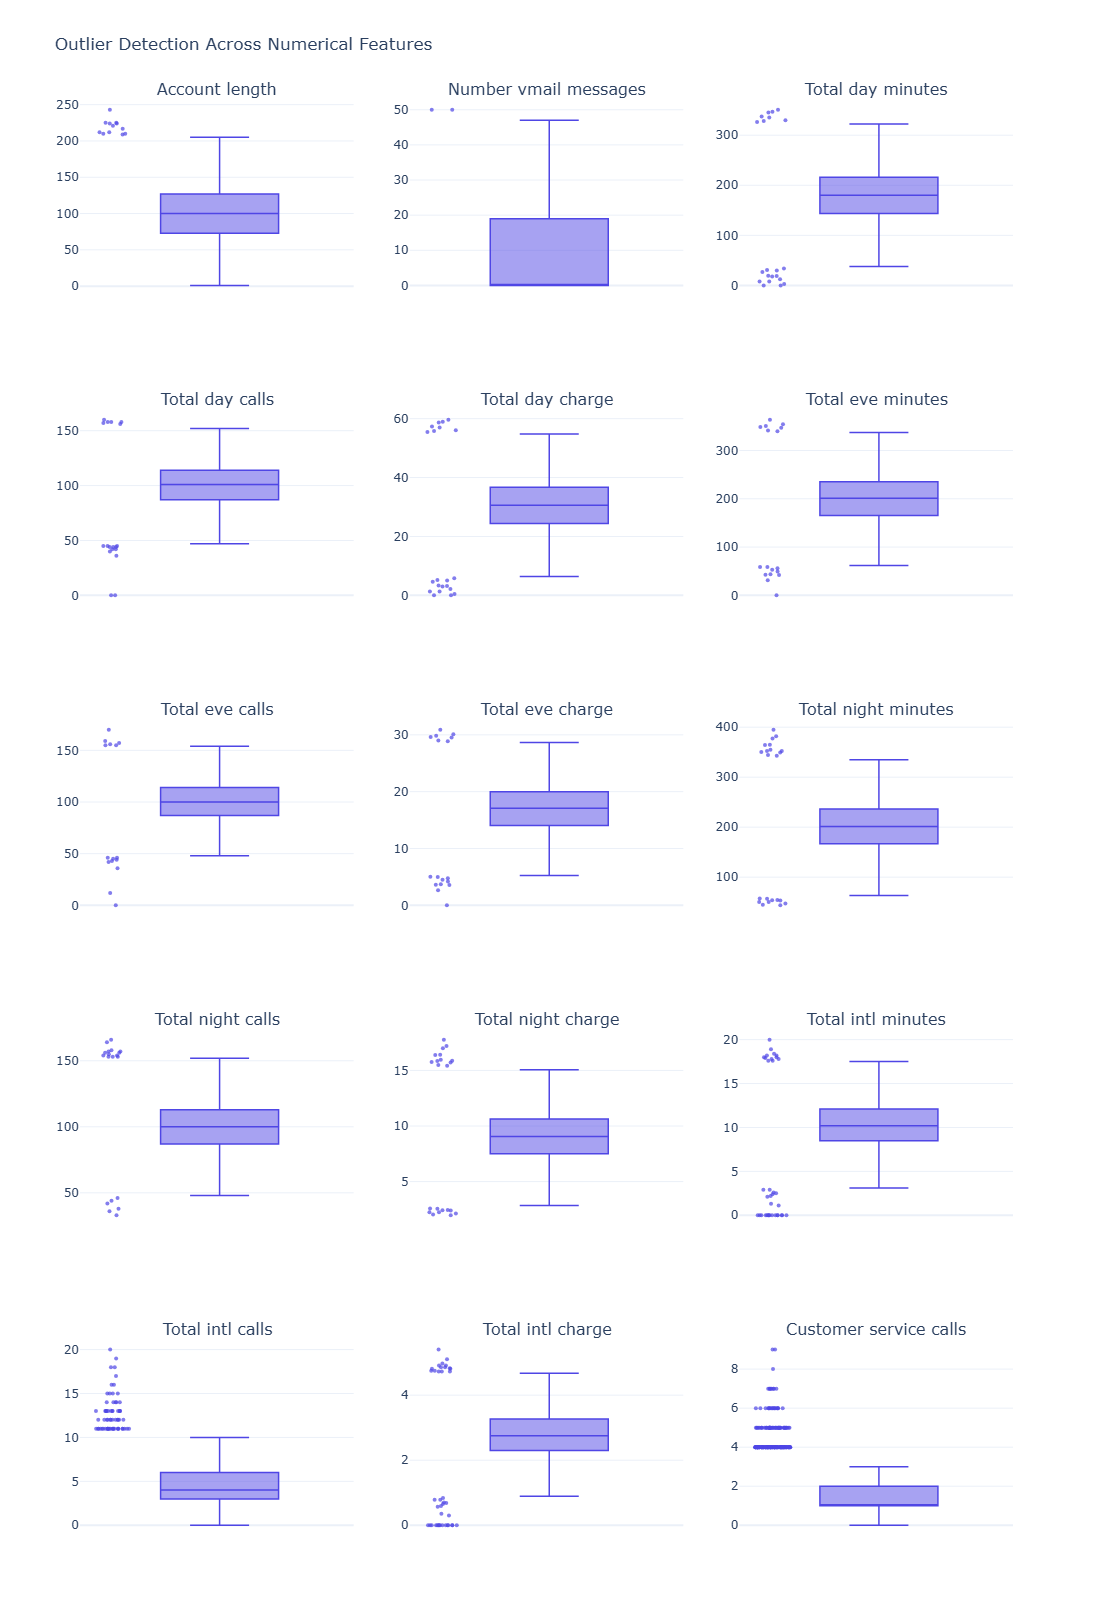

In [10]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
exclude_cols = ["Churn", "Area code"]  # adjust based on your dataframe
num_cols = [col for col in num_cols if col not in exclude_cols]

cols_per_row = 3
n_rows = int(np.ceil(len(num_cols) / cols_per_row))

fig = make_subplots(
    rows=n_rows,
    cols=cols_per_row,
    subplot_titles=num_cols,
    vertical_spacing=0.08,
    horizontal_spacing=0.06
)

for idx, col in enumerate(num_cols):
    row = (idx // cols_per_row) + 1
    c = (idx % cols_per_row) + 1
    
    fig.add_trace(
        go.Box(
            y=df[col],
            name="",
            boxpoints="outliers", 
            jitter=0.3,
            pointpos=-1.8,
            marker=dict(color="#4F46E5", size=4, opacity=0.7),
            line=dict(width=1.5)
        ),
        row=row,
        col=c
    )

fig.update_layout(
    height=320 * n_rows,
    width=1100,
    title_text="Outlier Detection Across Numerical Features",
    showlegend=False,
    template="plotly_white"
)
fig.show()

* Across all features, the outlier dots are sparse (mostly a dozen or fewer points per feature), representing a very small fraction of the total customer base.
* Do not drop these rows: None of the values look impossible (e.g., negative minutes or 1,000 calls).

### Bivariate Analysis

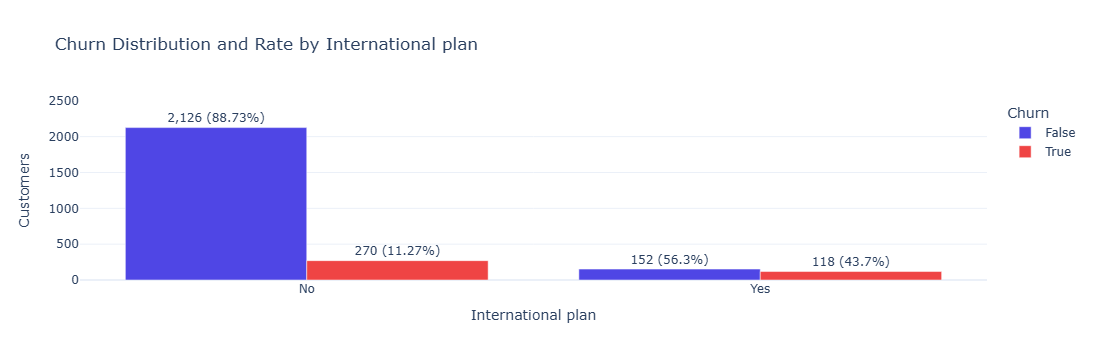

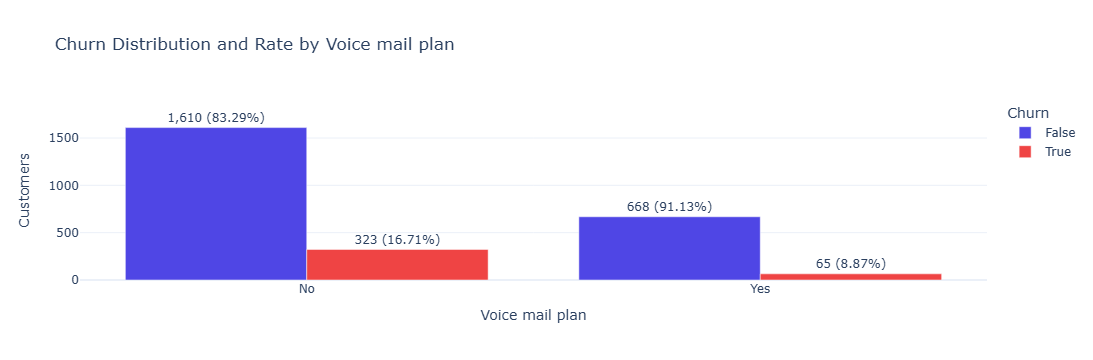

In [11]:
cat_cols = ["International plan", "Voice mail plan"]

for col in cat_cols:
    if col in df.columns:

        summary = (
            df.groupby([col, "Churn"])
            .size()
            .reset_index(name="Customer Count")
        )
        
        total_per_cat = summary.groupby(col)["Customer Count"].transform("sum")
        summary["Group Proportion (%)"] = (
            (summary["Customer Count"] / total_per_cat) * 100
        ).round(2)
        
        summary["Label"] = summary.apply(
            lambda r: f"{r['Customer Count']:,} ({r['Group Proportion (%)']}%)", 
            axis=1
        )
        
        fig = px.bar(
            summary,
            x=col,
            y="Customer Count",
            color="Churn",
            barmode="group",
            text="Label",
            title=f"Churn Distribution and Rate by {col}",
            template="plotly_white",
            color_discrete_map={0: "#4F46E5", 1: "#EF4444", False: "#4F46E5", True: "#EF4444"}
        )
        fig.update_traces(textposition="outside")
        fig.update_layout(yaxis_title="Customers", legend_title_text="Churn")
        fig.show()

* Customers with an International Plan churn at an alarming rate of 43.70% (118 churned out of 270 subscribers).
* Customers with a Voice Mail Plan churn at a low rate of 8.87% (65 churned out of 733). Customers using integrated value-added services are more tied to the carrier and harder to displace.

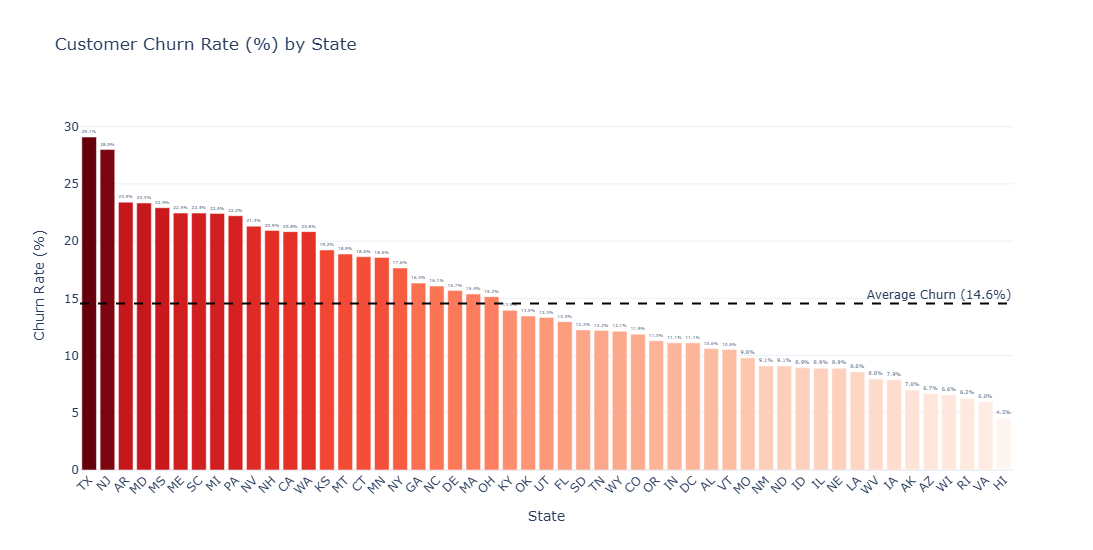

In [12]:
state_churn = (
    df.groupby("State")["Churn"]
    .agg(
        Total_Customers="count",
        Churned_Customers=lambda x: (x.isin([1, True])).sum()
    )
    .reset_index()
)

state_churn["Churn_Rate_%"] = (
    (state_churn["Churned_Customers"] / state_churn["Total_Customers"]) * 100
).round(2)

state_churn = state_churn.sort_values(by="Churn_Rate_%", ascending=False)

fig = px.bar(
    state_churn,
    x="State",
    y="Churn_Rate_%",
    text=state_churn["Churn_Rate_%"].apply(lambda x: f"{x:.1f}%"),
    color="Churn_Rate_%",
    color_continuous_scale="Reds",
    hover_data={
        "Total_Customers": True,
        "Churned_Customers": True,
        "Churn_Rate_%": ":.2f%"
    },
    title="Customer Churn Rate (%) by State",
    template="plotly_white"
)

overall_churn_rate = (df["Churn"].isin([1, True]).mean() * 100)
fig.add_hline(
    y=overall_churn_rate,
    line_dash="dash",
    line_color="black",
    annotation_text=f"Average Churn ({overall_churn_rate:.1f}%)",
    annotation_position="top right"
)

fig.update_traces(textposition="outside")
fig.update_layout(
    xaxis_tickangle=-45,
    yaxis_title="Churn Rate (%)",
    height=550,
    coloraxis_showscale=False
)
fig.show()

* Churn rates range from a high of 29.1% in Texas (TX) and 28.0% in New Jersey (NJ) down to a low of 4.5% in Hawaii (HI).
* In a small state sample (e.g., California with ~24 customers or Hawaii with ~40 customers), a shift of just 2 or 3 churned accounts causes large percentage swings.

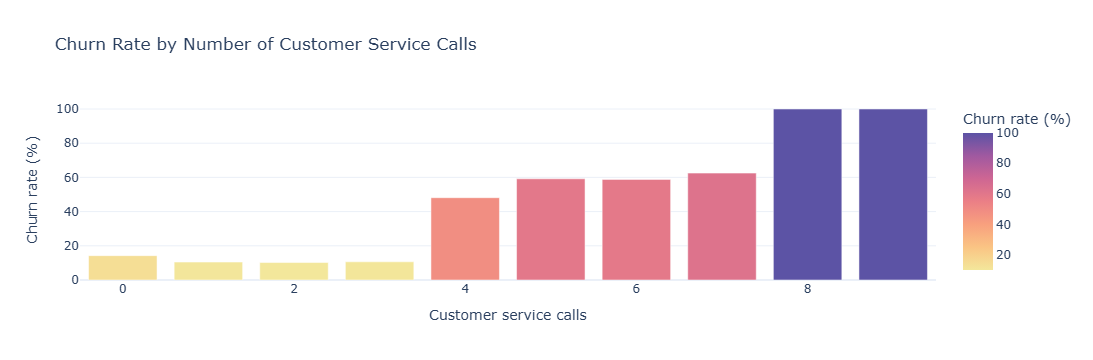

In [13]:
target = "Churn"
if "Customer service calls" in df.columns and target:
    svc = df.groupby("Customer service calls")[target].agg(
        customers="size", churn_rate="mean", churned="sum"
    ).reset_index()
    svc["churn_rate_pct"] = svc["churn_rate"] * 100

    fig = px.bar(svc, x="Customer service calls", y="churn_rate_pct",
                 hover_data=["customers", "churned"],
                 title="Churn Rate by Number of Customer Service Calls",
                 labels={"churn_rate_pct": "Churn rate (%)"},
                 template="plotly_white", color="churn_rate_pct",
                 color_continuous_scale="Sunset")
    fig.show()

* Churn Cliff: At exactly 4 calls, the churn rate suddenly leaps to roughly 48% to 50%.

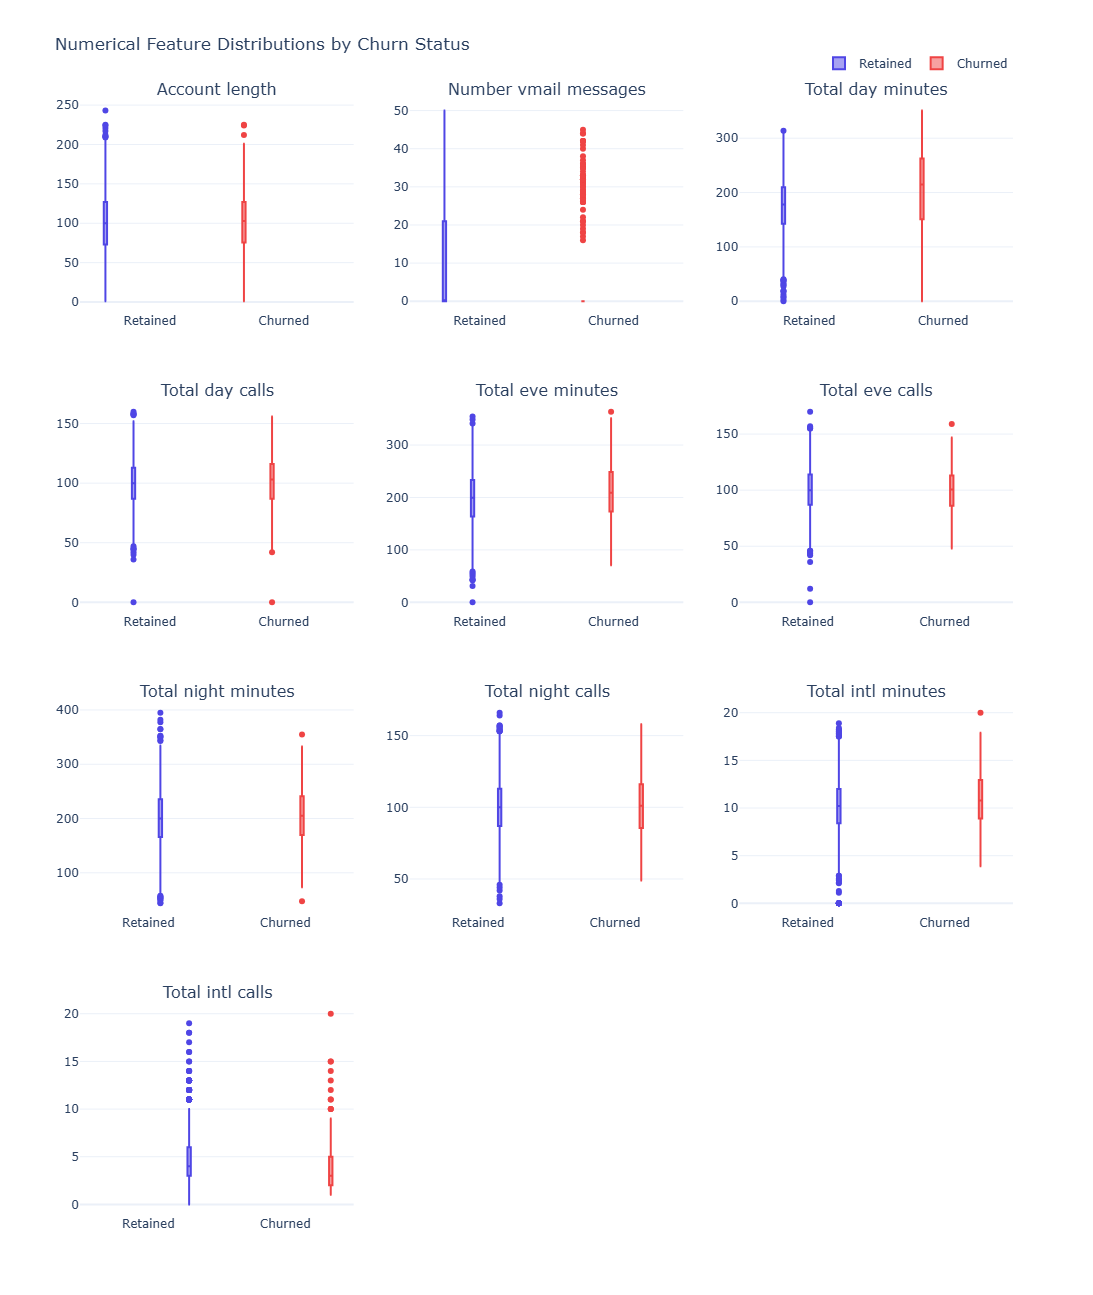

In [14]:
num_cols = [
    "Account length",
    "Number vmail messages",
    "Total day minutes",
    "Total day calls",
    "Total eve minutes",
    "Total eve calls",
    "Total night minutes",
    "Total night calls",
    "Total intl minutes",
    "Total intl calls",
]

num_cols = [c for c in num_cols if c in df.columns]

cols_per_row = 3
n_rows = int(np.ceil(len(num_cols) / cols_per_row))

fig = make_subplots(
    rows=n_rows,
    cols=cols_per_row,
    subplot_titles=num_cols,
    vertical_spacing=0.08,
    horizontal_spacing=0.06
)

for idx, col in enumerate(num_cols):
    row = (idx // cols_per_row) + 1
    c = (idx % cols_per_row) + 1
    
    fig.add_trace(
        go.Box(
            y=df[df["Churn"].isin([0, False])][col],
            name="Retained",
            marker_color="#4F46E5",
            showlegend=(idx == 0)
        ),
        row=row,
        col=c
    )
    
    fig.add_trace(
        go.Box(
            y=df[df["Churn"].isin([1, True])][col],
            name="Churned",
            marker_color="#EF4444",
            showlegend=(idx == 0)
        ),
        row=row,
        col=c
    )

fig.update_layout(
    height=320 * n_rows,
    width=1150,
    boxmode="group",
    title_text="Numerical Feature Distributions by Churn Status",
    template="plotly_white",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)
fig.show()

* Total day minutes (Strongest Continuous Signal):

    Distribution Shift: There is a noticeable upward shift in the churned group. Retained customers have a median around ~180 minutes, whereas churned customers have a median well above ~215 minutes, with the interquartile range stretching past 260 minutes.

    Business Insight: Heavy daytime talkers are actively churning. This confirms price sensitivity during daytime peak billing hours. High daytime spenders likely find cheaper unlimited daytime plans with competitors.

* Number vmail messages:

    Retained Profile: Retained customers have an active quartile reaching up to 20+ messages and a whisker extending up to 50 messages.

    Churned Profile: The churned box has completely collapsed to near 0 (almost entirely non-users), with only a few isolated outliers using voicemail.

    Business Insight: As identified earlier, active voicemail plan usage creates product stickiness; customers who don't engage with voicemail churn at significantly higher rates.

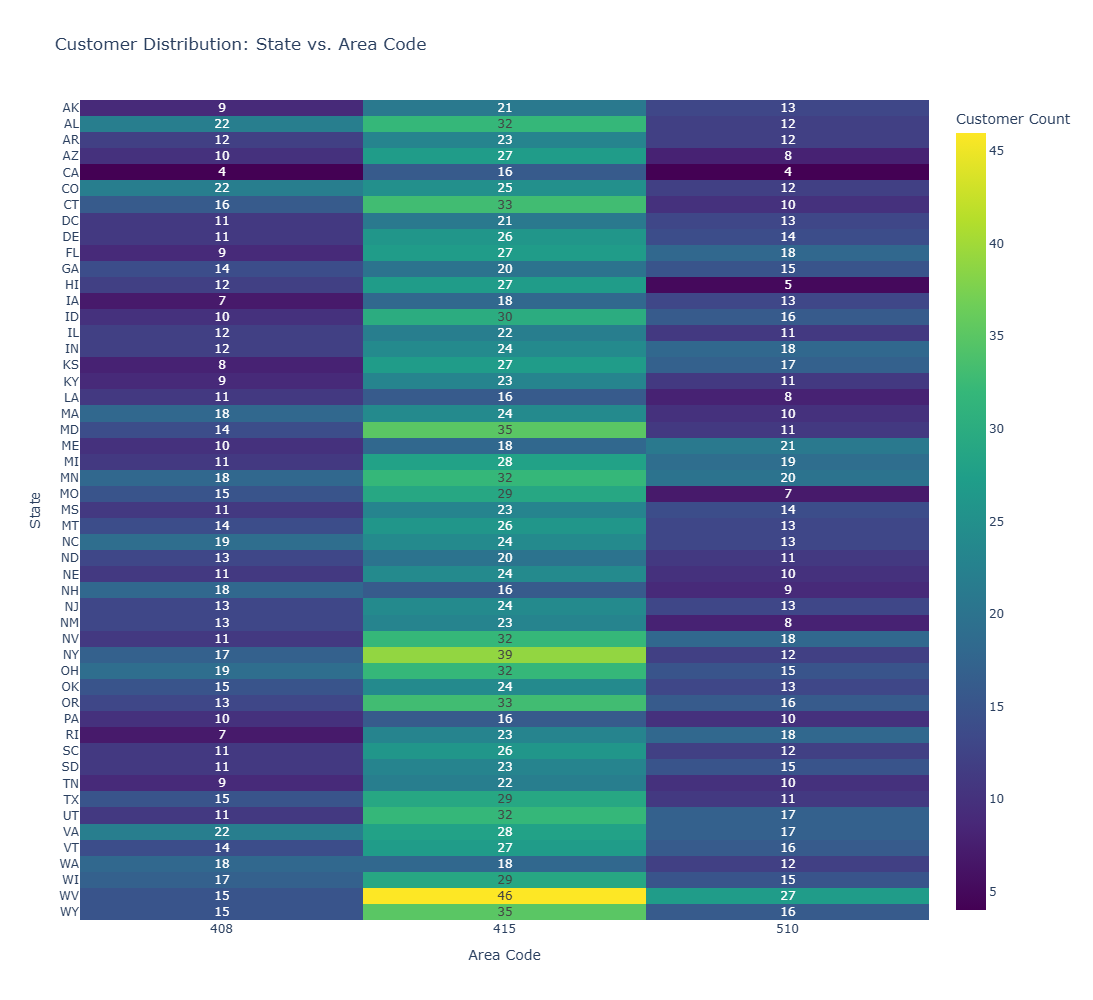

Average Area Code distribution across all states:
Area code
408    25.11
415    49.49
510    25.40
dtype: float64


In [15]:
ct = pd.crosstab(df['State'], df['Area code'])

ct_pct = pd.crosstab(df['State'], df['Area code'], normalize='index') * 100
fig = px.imshow(
    ct,
    labels=dict(x="Area Code", y="State", color="Customer Count"),
    x=ct.columns.astype(str),
    y=ct.index,
    color_continuous_scale="Viridis",
    title="Customer Distribution: State vs. Area Code",
    aspect="auto",
    text_auto=True
)

fig.update_layout(height=1000, width=650)
fig.show()

print("Average Area Code distribution across all states:")
print(ct_pct.mean().round(2))

* Drop Area code immediately. Because it is evenly distributed across all states, uncorrelated with churn, and devoid of real geographic meaning, retaining it adds pure noise to your feature set.

### Trivariate Analysis

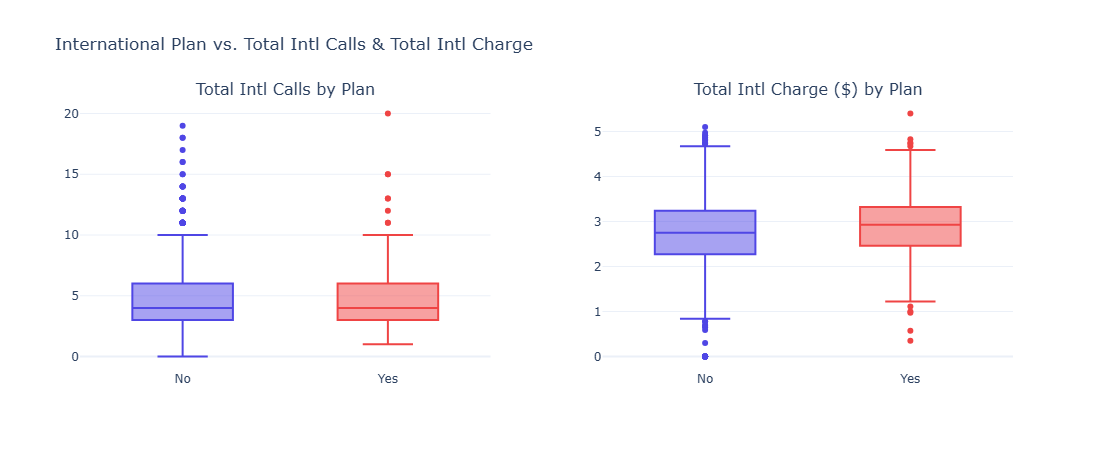

Effective Cost per International Minute:
International plan
No     0.2684
Yes    0.2700
Name: effective_intl_rate, dtype: float64


In [16]:
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=["Total Intl Calls by Plan", "Total Intl Charge ($) by Plan"],
    horizontal_spacing=0.12
)
for plan, color in zip(["No", "Yes"], ["#4F46E5", "#EF4444"]):
    fig.add_trace(
        go.Box(
            x=df[df["International plan"] == plan]["International plan"],
            y=df[df["International plan"] == plan]["Total intl calls"],
            name=f"Plan: {plan}",
            marker_color=color,
            showlegend=False
        ),
        row=1, col=1
    )

for plan, color in zip(["No", "Yes"], ["#4F46E5", "#EF4444"]):
    fig.add_trace(
        go.Box(
            x=df[df["International plan"] == plan]["International plan"],
            y=df[df["International plan"] == plan]["Total intl charge"],
            name=f"Plan: {plan}",
            marker_color=color,
            showlegend=False
        ),
        row=1, col=2
    )

fig.update_layout(
    title_text="International Plan vs. Total Intl Calls & Total Intl Charge",
    template="plotly_white",
    height=450,
    width=900
)
fig.show()

df['effective_intl_rate'] = df['Total intl charge'] / (df['Total intl minutes'] + 1e-6)
rate_comparison = df.groupby('International plan')['effective_intl_rate'].mean().round(4)
print("Effective Cost per International Minute:")
print(rate_comparison)

1. Paying for an international plan does not lead customers to make more international calls.
2. The international plan provides zero per-minute price advantage on usage charges.
3. Why International Plan Subscribers Churn at 43.7%Customers who opt into an "International Plan" typically expect discounted call rates or free bundled minutes in exchange for paying a recurring subscription fee.   In this carrier's setup, subscribers pay for the plan yet are charged the standard rate of $0.27 per minute on their calls.   This double-billing structure (paying for a plan that delivers no per-minute savings) creates severe customer dissatisfaction and directly explains the 43.7% churn rate among plan subscribers.

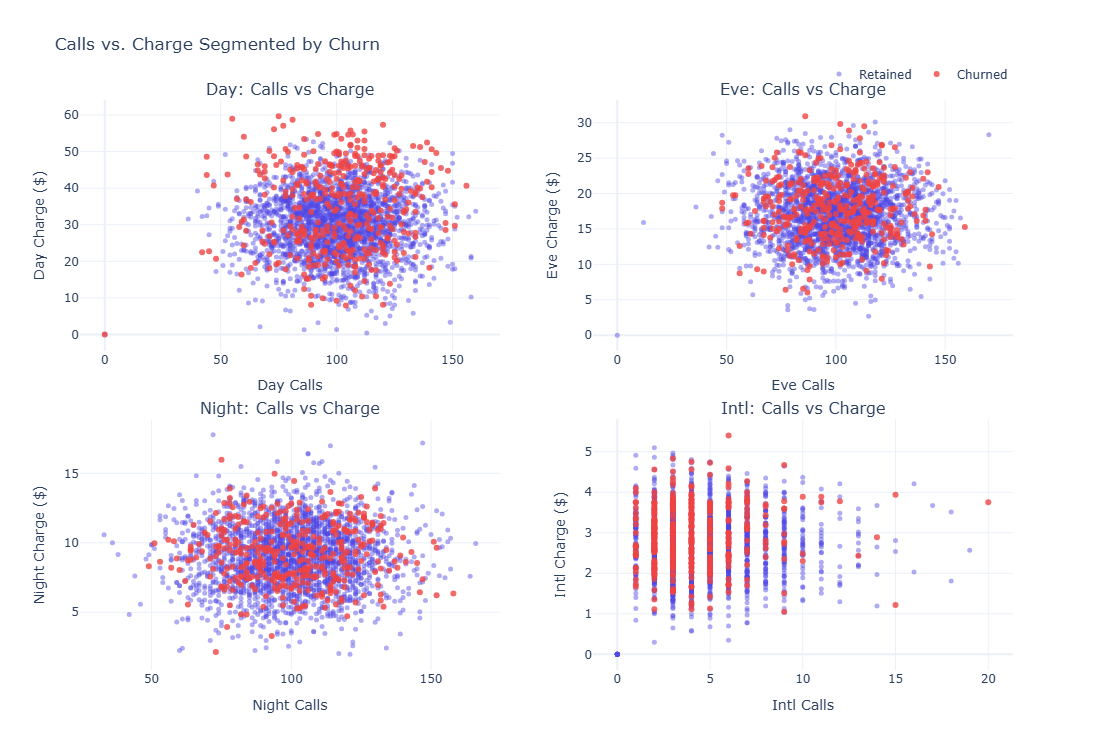

In [17]:
periods = [
    ("Total day calls", "Total day charge", "Day: Calls vs Charge"),
    ("Total eve calls", "Total eve charge", "Eve: Calls vs Charge"),
    ("Total night calls", "Total night charge", "Night: Calls vs Charge"),
    ("Total intl calls", "Total intl charge", "Intl: Calls vs Charge"),
]

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=[p[2] for p in periods],
    horizontal_spacing=0.1,
    vertical_spacing=0.12
)

for idx, (call_col, charge_col, title) in enumerate(periods):
    row = (idx // 2) + 1
    col = (idx % 2) + 1
    
    retained = df[df["Churn"].isin([0, False])]
    fig.add_trace(
        go.Scatter(
            x=retained[call_col],
            y=retained[charge_col],
            mode="markers",
            name="Retained",
            marker=dict(color="#4F46E5", size=5, opacity=0.45),
            showlegend=(idx == 0)
        ),
        row=row, col=col
    )
    
    churned = df[df["Churn"].isin([1, True])]
    fig.add_trace(
        go.Scatter(
            x=churned[call_col],
            y=churned[charge_col],
            mode="markers",
            name="Churned",
            marker=dict(color="#EF4444", size=6, opacity=0.8),
            showlegend=(idx == 0)
        ),
        row=row, col=col
    )

fig.update_layout(
    height=750,
    width=1050,
    title_text="Calls vs. Charge Segmented by Churn",
    template="plotly_white",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)

fig.update_xaxes(title_text="Day Calls", row=1, col=1)
fig.update_yaxes(title_text="Day Charge ($)", row=1, col=1)

fig.update_xaxes(title_text="Eve Calls", row=1, col=2)
fig.update_yaxes(title_text="Eve Charge ($)", row=1, col=2)

fig.update_xaxes(title_text="Night Calls", row=2, col=1)
fig.update_yaxes(title_text="Night Charge ($)", row=2, col=1)

fig.update_xaxes(title_text="Intl Calls", row=2, col=2)
fig.update_yaxes(title_text="Intl Charge ($)", row=2, col=2)

fig.show()

* Day Calls, Eve Calls, and Night Calls show less separation from retained customers across all charge levels. These features add noise and can safely be dropped or de-prioritized or new features can be created.

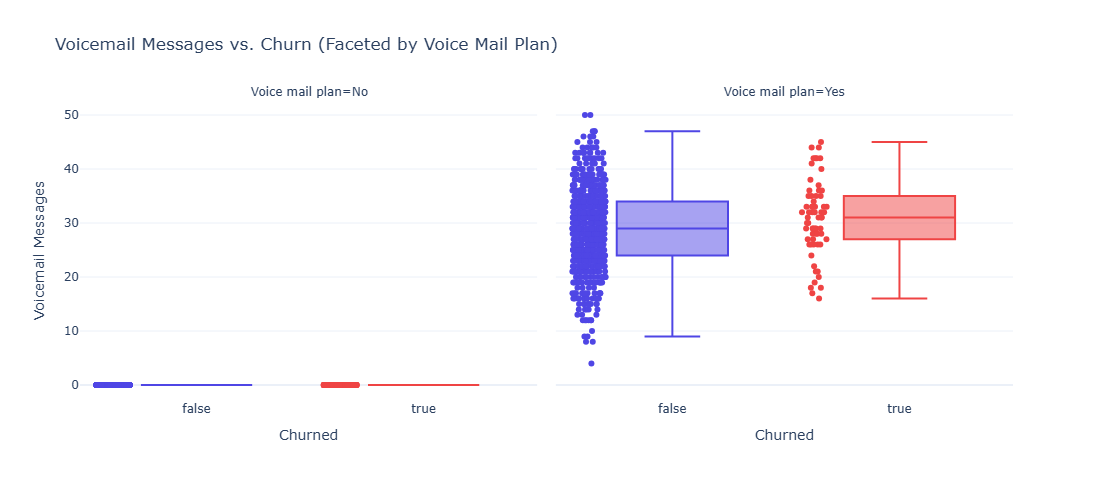

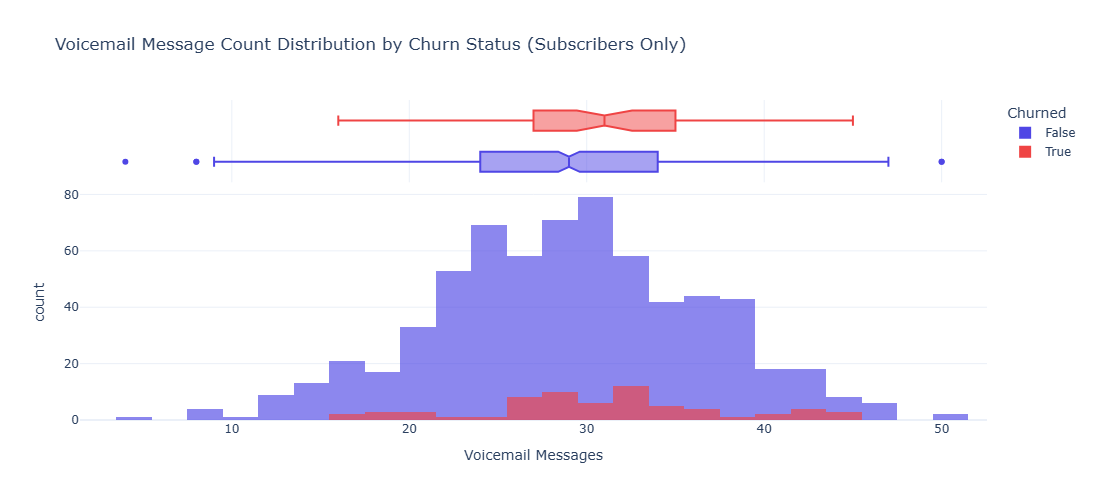

In [18]:
fig1 = px.box(
    df,
    x="Churn",
    y="Number vmail messages",
    color="Churn",
    facet_col="Voice mail plan",
    category_orders={"Voice mail plan": ["No", "Yes"], "Churn": [False, True]},
    points="all",
    title="Voicemail Messages vs. Churn (Faceted by Voice Mail Plan)",
    labels={
        "Number vmail messages": "Voicemail Messages",
        "Churn": "Churned"
    },
    template="plotly_white",
    color_discrete_map={False: "#4F46E5", True: "#EF4444", 0: "#4F46E5", 1: "#EF4444"}
)

fig1.update_layout(height=480, width=900, showlegend=False)
fig1.show()

vmail_subs = df[df["Voice mail plan"] == "Yes"]

fig2 = px.histogram(
    vmail_subs,
    x="Number vmail messages",
    color="Churn",
    barmode="overlay",
    marginal="box",
    nbins=25,
    title="Voicemail Message Count Distribution by Churn Status (Subscribers Only)",
    labels={"Number vmail messages": "Voicemail Messages", "Churn": "Churned"},
    template="plotly_white",
    color_discrete_map={False: "#4F46E5", True: "#EF4444", 0: "#4F46E5", 1: "#EF4444"},
    opacity=0.65
)

fig2.update_layout(height=500, width=900)
fig2.show()

* Drop Number vmail messages & Retain Voice mail plan: because the overlaid histogram shows that both retained and churned cohorts follow the exact same bell-shaped curve spanning roughly 15 to 45 messages. Because non-subscribers are identically 0 and subscribers show zero volume-based churn differentiation, Number vmail messages acts as a redundant, noisy proxy for Voice mail plan.

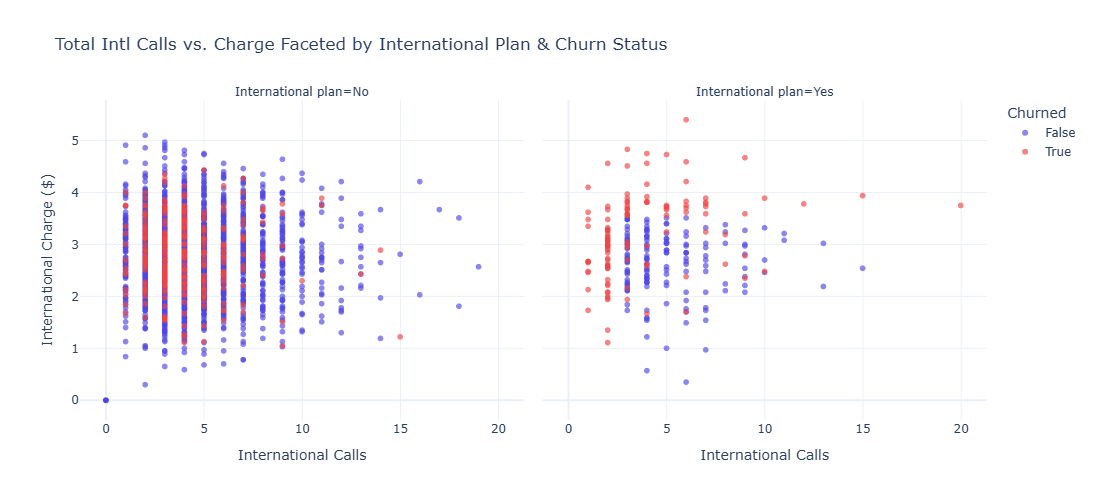

In [19]:
fig = px.scatter(
    df,
    x="Total intl calls",
    y="Total intl charge",
    color="Churn",
    facet_col="International plan",
    category_orders={"International plan": ["No", "Yes"]},
    color_discrete_map={0: "#4F46E5", 1: "#EF4444", False: "#4F46E5", True: "#EF4444"},
    title="Total Intl Calls vs. Charge Faceted by International Plan & Churn Status",
    labels={
        "Total intl calls": "International Calls",
        "Total intl charge": "International Charge ($)",
        "Churn": "Churned"
    },
    opacity=0.65,
    template="plotly_white"
)

fig.update_traces(marker=dict(size=6))
fig.update_layout(height=500, width=950)
fig.show()

* Non-Subscribers: The vast majority of points are blue (Churned = False), reflecting the low baseline churn rate.
* Subscribers: Red points (Churned = True) dominate the panel, visually confirming the high churn rate.
* Subscribing to an international plan does not increase the frequency of international calling.